# Лабораторная работа 9. Использование многослойного персептрона в задаче классификации

In [1]:
import os
import gzip
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision.transforms import v2
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

torch.set_num_threads(4)
os.makedirs("artifacts", exist_ok=True)

print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())
print("Потоков CPU:", torch.get_num_threads())

PyTorch: 2.10.0+cpu
CUDA доступна: False
Потоков CPU: 4


## Учебная задача. Классификация Fashion-MNIST

In [2]:
base_dir = "datasets/fashionmnist"
os.makedirs(base_dir, exist_ok=True)

urls = {
    "train-images-idx3-ubyte.gz": "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz": "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz": "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz": "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-labels-idx1-ubyte.gz",
}


def read_idx_images(path):
    with gzip.open(path, "rb") as f:
        f.read(4)
        n = int.from_bytes(f.read(4), "big")
        rows = int.from_bytes(f.read(4), "big")
        cols = int.from_bytes(f.read(4), "big")
        data = np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows * cols)
    return data


def read_idx_labels(path):
    with gzip.open(path, "rb") as f:
        f.read(4)
        n = int.from_bytes(f.read(4), "big")
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data


for split, img_name, lbl_name in [
    ("train", "train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"),
    ("test", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"),
]:
    csv_path = os.path.join(base_dir, f"fashion-mnist_{split}.csv")
    if os.path.exists(csv_path):
        continue
    for name, url in urls.items():
        path = os.path.join(base_dir, name)
        if not os.path.exists(path):
            urllib.request.urlretrieve(url, path)
    X = read_idx_images(os.path.join(base_dir, img_name))
    y = read_idx_labels(os.path.join(base_dir, lbl_name))
    df = pd.DataFrame(X)
    df.insert(0, "label", y)
    df.to_csv(csv_path, index=False)

print("Файлы готовы")

Файлы готовы


In [3]:
train_df = pd.read_csv(os.path.join(base_dir, "fashion-mnist_train.csv"))
test_df = pd.read_csv(os.path.join(base_dir, "fashion-mnist_test.csv"))

print("Обучающая выборка:", train_df.shape)
print("Тестовая выборка:", test_df.shape)

classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(train_df["label"].value_counts().sort_index())
train_df.head()

Обучающая выборка: (60000, 785)
Тестовая выборка: (10000, 785)
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


,label,0,1,2,3,4,5,6,7,8,...,774,775,776,777,778,779,780,781,782,783
0,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,119,114,130,76,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,33,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


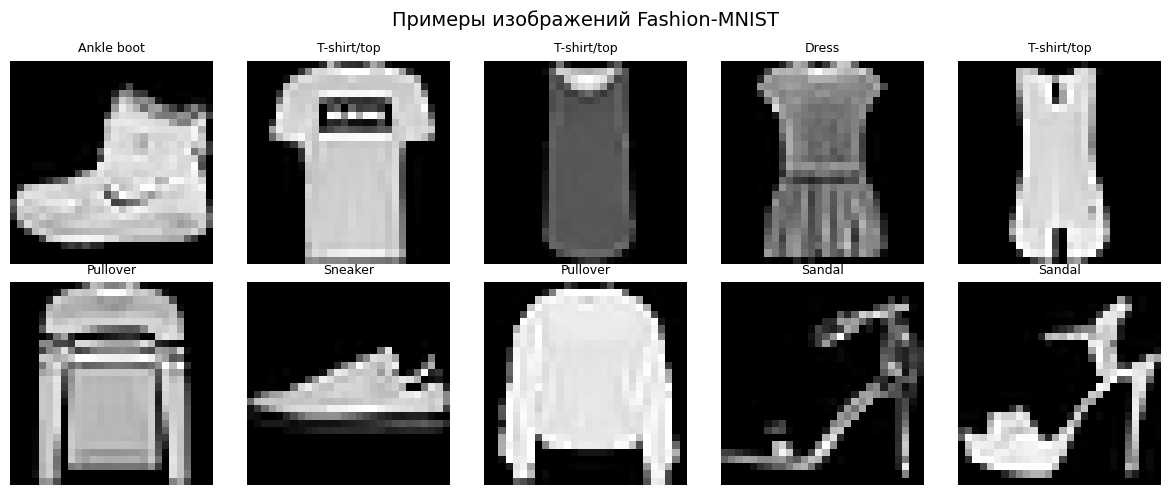

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(train_df.iloc[i, 1:].values.reshape(28, 28), cmap="gray")
    ax.set_title(classes[train_df.iloc[i, 0]], fontsize=9)
    ax.axis("off")
plt.suptitle("Примеры изображений Fashion-MNIST", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig01_samples.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
X_train = train_df.values[:, 1:]
y_train = train_df.values[:, 0]

X_test = test_df.values[:, 1:]
y_test = test_df.values[:, 0]

X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.LongTensor(y_train.astype(np.int64))

print(X_train_tensor.shape, y_train_tensor.shape)
print(y_train_tensor.unique())

length = y_train_tensor.shape[0]
num_classes = 10
y_onehot = torch.FloatTensor(length, num_classes)
y_onehot.zero_()
y_onehot.scatter_(1, y_train_tensor.view(-1, 1), 1)

print(y_train_tensor[:10])
print(y_onehot[:10])

torch.Size([60000, 784]) torch.Size([60000])
tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
tensor([9, 0, 0, 3, 0, 2, 7, 2, 5, 5])
tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.]])


In [6]:
D_in, H, D_out = 784, 100, 10

torch.manual_seed(0)

net = nn.Sequential(
    nn.Linear(D_in, H),
    nn.ReLU(),
    nn.Linear(H, D_out),
    nn.Softmax(dim=1),
)
net

Sequential(
  (0): Linear(in_features=784, out_features=100, bias=True)
  (1): ReLU()
  (2): Linear(in_features=100, out_features=10, bias=True)
  (3): Softmax(dim=1)
)

In [7]:
def generate_batches(X, y, batch_size=64):
    for i in range(0, X.shape[0], batch_size):
        yield X[i:i + batch_size], y[i:i + batch_size]


BATCH_SIZE = 64
NUM_EPOCHS = 100

loss_fn = nn.CrossEntropyLoss(reduction="sum")
learning_rate = 1e-4
optimizer = torch.optim.SGD(net.parameters(), lr=learning_rate)

for epoch_num in range(NUM_EPOCHS):
    running_loss = 0.0
    for X_batch, y_batch in generate_batches(X_train_tensor, y_train_tensor, BATCH_SIZE):
        y_pred = net(X_batch)
        loss = loss_fn(y_pred, y_batch)
        running_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch_num % 10 == 0 or epoch_num == NUM_EPOCHS - 1:
        print("Эпоха {:3d}: средняя потеря {:.4f}".format(
            epoch_num, running_loss / len(X_train_tensor)))

Эпоха   0: средняя потеря 2.1997


Эпоха  10: средняя потеря 1.7305


Эпоха  20: средняя потеря 1.7204


Эпоха  30: средняя потеря 1.7148


Эпоха  40: средняя потеря 1.7114


Эпоха  50: средняя потеря 1.6348


Эпоха  60: средняя потеря 1.6293


Эпоха  70: средняя потеря 1.6291


Эпоха  80: средняя потеря 1.6288


Эпоха  90: средняя потеря 1.6201


Эпоха  99: средняя потеря 1.6152


In [8]:
class_correct = list(0. for i in range(10))
class_total = list(0. for i in range(10))

with torch.no_grad():
    for X_batch, y_batch in generate_batches(X_train_tensor, y_train_tensor, BATCH_SIZE):
        y_pred = net(X_batch)
        _, predicted = torch.max(y_pred, 1)
        c = (predicted == y_batch).squeeze()
        for i in range(len(y_pred)):
            label = y_batch[i]
            class_correct[label] += c[i].item()
            class_total[label] += 1

for i in range(10):
    print("Accuracy of %5s : %2d %%" % (
        classes[i], 100 * class_correct[i] / class_total[i]))

Accuracy of T-shirt/top : 90 %
Accuracy of Trouser : 97 %
Accuracy of Pullover : 81 %
Accuracy of Dress : 88 %
Accuracy of  Coat : 88 %
Accuracy of Sandal : 97 %
Accuracy of Shirt : 11 %
Accuracy of Sneaker : 97 %
Accuracy of   Bag : 97 %
Accuracy of Ankle boot : 97 %


In [9]:
y_test_pred = net(torch.FloatTensor(X_test))
print(y_test_pred.shape)
print(y_test_pred[:5])

_, predicted = torch.max(y_test_pred, 1)

answer_df = pd.DataFrame(data=predicted.numpy(), columns=["Category"])
answer_df["Id"] = answer_df.index
answer_df.to_csv("artifacts/baseline.csv", index=False)

baseline_pred = predicted.numpy()
baseline_acc = accuracy_score(y_test, baseline_pred)
baseline_f1 = f1_score(y_test, baseline_pred, average="macro")

print(answer_df.head())
print("Baseline test accuracy:", round(baseline_acc, 4))
print("Baseline macro F1:", round(baseline_f1, 4))

torch.Size([10000, 10])
tensor([[0.0000e+00, 0.0000e+00, 0.0000e+00, 4.7644e-44, 0.0000e+00, 1.1412e-32,
         0.0000e+00, 1.5140e-28, 0.0000e+00, 1.0000e+00],
        [0.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [1.0483e-02, 2.1057e-29, 9.3590e-05, 4.0228e-35, 0.0000e+00, 5.4869e-24,
         9.8942e-01, 8.8811e-36, 5.6395e-27, 1.0654e-26]],
       grad_fn=<SliceBackward0>)
   Category  Id
0         9   0
1         2   1
2         1   2
3         1   3
4         6   4
Baseline test accuracy: 0.8315
Baseline macro F1: 0.8107


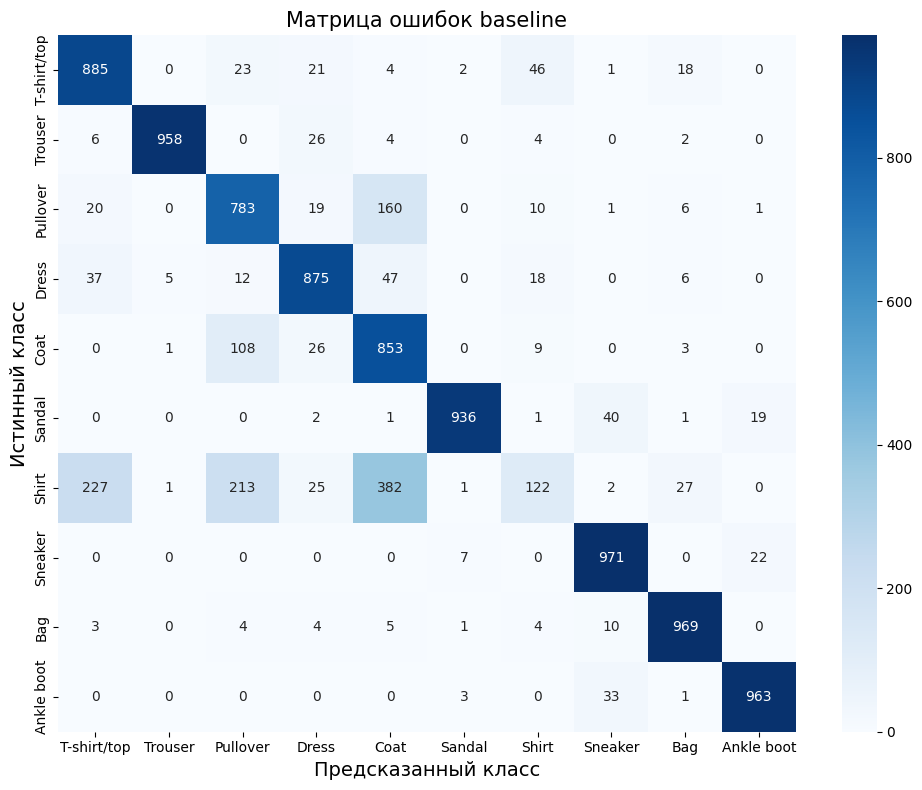

              precision    recall  f1-score   support

 T-shirt/top      0.751     0.885     0.813      1000
     Trouser      0.993     0.958     0.975      1000
    Pullover      0.685     0.783     0.731      1000
       Dress      0.877     0.875     0.876      1000
        Coat      0.586     0.853     0.695      1000
      Sandal      0.985     0.936     0.960      1000
       Shirt      0.570     0.122     0.201      1000
     Sneaker      0.918     0.971     0.944      1000
         Bag      0.938     0.969     0.953      1000
  Ankle boot      0.958     0.963     0.961      1000

    accuracy                          0.832     10000
   macro avg      0.826     0.831     0.811     10000
weighted avg      0.826     0.832     0.811     10000

Точность baseline по классам:
T-shirt/top  0.885
Trouser      0.958
Pullover     0.783
Dress        0.875
Coat         0.853
Sandal       0.936
Shirt        0.122
Sneaker      0.971
Bag          0.969
Ankle boot   0.963


In [10]:
cm_baseline = confusion_matrix(y_test, baseline_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_baseline, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Матрица ошибок baseline", fontsize=15)
plt.xlabel("Предсказанный класс", fontsize=14)
plt.ylabel("Истинный класс", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig02_baseline_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(y_test, baseline_pred, target_names=classes, digits=3))

print("Точность baseline по классам:")
for i, name in enumerate(classes):
    mask = y_test == i
    print("%-12s %.3f" % (name, accuracy_score(y_test[mask], baseline_pred[mask])))

In [11]:
import gc

del X_train_tensor, y_train_tensor, y_onehot
gc.collect()
print("Память после baseline освобождена")

Память после baseline освобождена

## Индивидуальное задание. Повышение качества классификации

In [12]:
X_train_norm = (X_train / 255.0 - 0.2860) / 0.3530
X_test_norm = (X_test / 255.0 - 0.2860) / 0.3530

idx_tr, idx_val = train_test_split(
    np.arange(len(X_train)), test_size=5000, random_state=42, stratify=y_train)

X_tr = X_train_norm[idx_tr]
y_tr = y_train[idx_tr]
X_val = X_train_norm[idx_val]
y_val = y_train[idx_val]

X_tr_t = torch.tensor(X_tr, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr, dtype=torch.long)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)

print("Обучение:", X_tr_t.shape, "Валидация:", X_val_t.shape, "Тест:", X_test_norm.shape)

Обучение: torch.Size([55000, 784]) Валидация: torch.Size([5000, 784]) Тест: (10000, 784)


In [13]:
torch.manual_seed(0)

mlp = nn.Sequential(
    nn.Linear(784, 512),
    nn.BatchNorm1d(512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 10),
)

loss_fn = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)

batch_size = 128
best_val = 0.0
best_state = None
mlp_losses = []
mlp_val_accs = []

for epoch in range(20):
    mlp.train()
    perm = torch.randperm(len(X_tr_t))
    running = 0.0
    for i in range(0, len(X_tr_t), batch_size):
        idx = perm[i:i + batch_size]
        out = mlp(X_tr_t[idx])
        loss = loss_fn(out, y_tr_t[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(idx)
    scheduler.step()

    mlp.eval()
    with torch.no_grad():
        val_pred = mlp(X_val_t).argmax(1)
    val_acc = (val_pred == y_val_t).float().mean().item()

    mlp_losses.append(running / len(X_tr_t))
    mlp_val_accs.append(val_acc)

    if val_acc > best_val:
        best_val = val_acc
        best_state = {k: v.clone() for k, v in mlp.state_dict().items()}

    print("Эпоха {:02d}: loss={:.4f}, val_acc={:.4f}".format(
        epoch + 1, mlp_losses[-1], val_acc))

mlp.load_state_dict(best_state)
print("Лучшая валидационная точность:", round(best_val, 4))

Эпоха 01: loss=0.7229, val_acc=0.8778


Эпоха 02: loss=0.6307, val_acc=0.8868


Эпоха 03: loss=0.6028, val_acc=0.8834


Эпоха 04: loss=0.5822, val_acc=0.8964


Эпоха 05: loss=0.5692, val_acc=0.8948


Эпоха 06: loss=0.5567, val_acc=0.9008


... (10 outputs left out)

Эпоха 17: loss=0.4487, val_acc=0.9156


Эпоха 18: loss=0.4422, val_acc=0.9170


Эпоха 19: loss=0.4363, val_acc=0.9160


Эпоха 20: loss=0.4358, val_acc=0.9154
Лучшая валидационная точность: 0.917


MLP test accuracy: 0.9063
MLP macro F1: 0.9061
              precision    recall  f1-score   support

 T-shirt/top      0.857     0.866     0.862      1000
     Trouser      0.994     0.979     0.986      1000
    Pullover      0.820     0.850     0.835      1000
       Dress      0.903     0.915     0.909      1000
        Coat      0.837     0.849     0.843      1000
      Sandal      0.980     0.970     0.975      1000
       Shirt      0.771     0.728     0.749      1000
     Sneaker      0.951     0.969     0.960      1000
         Bag      0.979     0.972     0.975      1000
  Ankle boot      0.969     0.965     0.967      1000

    accuracy                          0.906     10000
   macro avg      0.906     0.906     0.906     10000
weighted avg      0.906     0.906     0.906     10000



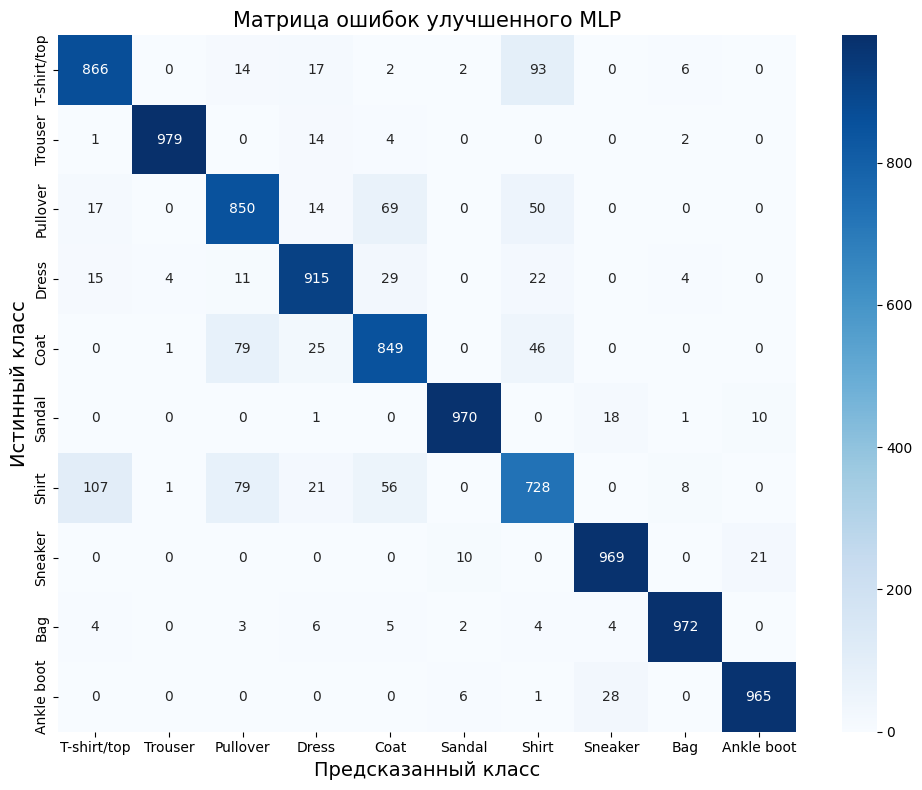

In [14]:
mlp.eval()
with torch.no_grad():
    mlp_pred = mlp(torch.tensor(X_test_norm, dtype=torch.float32)).argmax(1).numpy()

mlp_acc = accuracy_score(y_test, mlp_pred)
mlp_f1 = f1_score(y_test, mlp_pred, average="macro")

print("MLP test accuracy:", round(mlp_acc, 4))
print("MLP macro F1:", round(mlp_f1, 4))
print(classification_report(y_test, mlp_pred, target_names=classes, digits=3))

cm_mlp = confusion_matrix(y_test, mlp_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_mlp, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Матрица ошибок улучшенного MLP", fontsize=15)
plt.xlabel("Предсказанный класс", fontsize=14)
plt.ylabel("Истинный класс", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig03_mlp_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
import gc

X_train_f32 = X_train.astype(np.float32)
X_test_f32 = X_test.astype(np.float32)

del X_train, X_test, train_df, test_df
del X_train_norm, X_test_norm, X_tr, X_val, X_tr_t, X_val_t
gc.collect()
print("Память перед CNN освобождена")

Память перед CNN освобождена


In [16]:
X_train_cnn = (X_train_f32.reshape(-1, 1, 28, 28) / 255.0)
X_test_cnn = (X_test_f32.reshape(-1, 1, 28, 28) / 255.0)

X_tr_cnn = X_train_cnn[idx_tr]
X_val_cnn = X_train_cnn[idx_val]
del X_train_cnn
gc.collect()

augment = v2.Compose([
    v2.RandomCrop(28, padding=2),
    v2.RandomHorizontalFlip(),
])

train_ds = TensorDataset(torch.from_numpy(X_tr_cnn), torch.from_numpy(y_tr))
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True, num_workers=0)


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.25),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.25),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def predict_in_batches(model, X, batch_size=512):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            preds.append(model(X[i:i + batch_size]).argmax(1))
    return torch.cat(preds)


def predict_tta(model, X, batch_size=512):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = X[i:i + batch_size]
            logits = model(xb) + model(torch.flip(xb, dims=[3]))
            preds.append(logits.argmax(1))
    return torch.cat(preds)


X_val_cnn_norm = ((torch.tensor(X_val_cnn) - 0.2860) / 0.3530).contiguous(
    memory_format=torch.channels_last)
X_test_cnn_norm = ((torch.tensor(X_test_cnn) - 0.2860) / 0.3530).contiguous(
    memory_format=torch.channels_last)

In [17]:
torch.manual_seed(0)

cnn = CNN().to(memory_format=torch.channels_last)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=12)

best_val = 0.0
best_state = None
train_losses = []
val_accs = []

for epoch in range(12):
    start = time.time()
    cnn.train()
    running = 0.0
    for xb, yb in train_loader:
        xb = augment(xb)
        xb = ((xb - 0.2860) / 0.3530).contiguous(memory_format=torch.channels_last)

        out = cnn(xb)
        loss = loss_fn(out, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(xb)

    scheduler.step()
    train_losses.append(running / len(X_tr_cnn))

    val_pred = predict_in_batches(cnn, X_val_cnn_norm)
    val_acc = (val_pred == torch.tensor(y_val)).float().mean().item()
    val_accs.append(val_acc)

    if val_acc > best_val:
        best_val = val_acc
        best_state = {k: v.clone() for k, v in cnn.state_dict().items()}

    print("Эпоха {:02d}: loss={:.4f}, val_acc={:.4f}, время={:.1f} с".format(
        epoch + 1, train_losses[-1], val_acc, time.time() - start))

cnn.load_state_dict(best_state)
print("Лучшая валидационная точность:", round(best_val, 4))

Эпоха 01: loss=0.8911, val_acc=0.8594, время=93.4 с


Эпоха 02: loss=0.6983, val_acc=0.8998, время=91.5 с


Эпоха 03: loss=0.6512, val_acc=0.9072, время=95.4 с


Эпоха 04: loss=0.6174, val_acc=0.9180, время=92.1 с


Эпоха 05: loss=0.6007, val_acc=0.9216, время=94.2 с


Эпоха 06: loss=0.5798, val_acc=0.9226, время=94.3 с


... (2 outputs left out)

Эпоха 09: loss=0.5501, val_acc=0.9316, время=93.6 с


Эпоха 10: loss=0.5456, val_acc=0.9360, время=90.9 с


Эпоха 11: loss=0.5373, val_acc=0.9342, время=94.1 с


Эпоха 12: loss=0.5391, val_acc=0.9344, время=98.5 с
Лучшая валидационная точность: 0.936


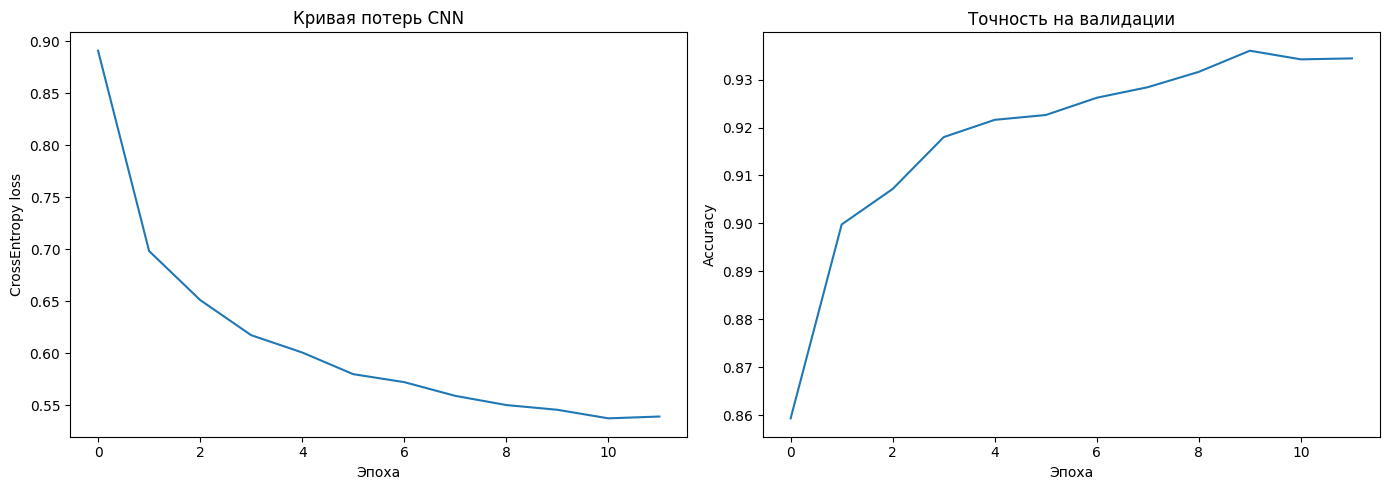

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_losses)
axes[0].set_title("Кривая потерь CNN")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("CrossEntropy loss")
axes[1].plot(val_accs)
axes[1].set_title("Точность на валидации")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
plt.tight_layout()
plt.savefig("figures/fig04_cnn_curves.png", dpi=150, bbox_inches="tight")
plt.show()

CNN test accuracy (TTA): 0.9211
CNN macro F1 (TTA): 0.9209
              precision    recall  f1-score   support

 T-shirt/top      0.876     0.868     0.872      1000
     Trouser      0.993     0.984     0.988      1000
    Pullover      0.895     0.887     0.891      1000
       Dress      0.924     0.922     0.923      1000
        Coat      0.854     0.913     0.883      1000
      Sandal      0.987     0.976     0.981      1000
       Shirt      0.776     0.743     0.759      1000
     Sneaker      0.950     0.973     0.961      1000
         Bag      0.985     0.983     0.984      1000
  Ankle boot      0.970     0.962     0.966      1000

    accuracy                          0.921     10000
   macro avg      0.921     0.921     0.921     10000
weighted avg      0.921     0.921     0.921     10000



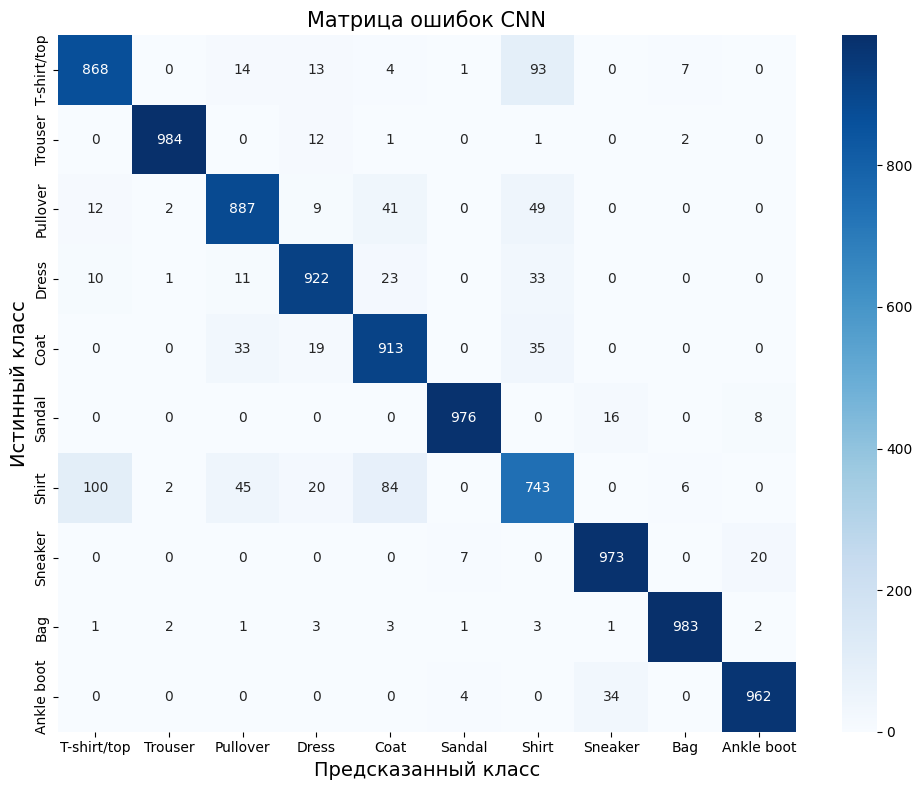

In [19]:
cnn_pred = predict_tta(cnn, X_test_cnn_norm).numpy()

cnn_acc = accuracy_score(y_test, cnn_pred)
cnn_f1 = f1_score(y_test, cnn_pred, average="macro")

print("CNN test accuracy (TTA):", round(cnn_acc, 4))
print("CNN macro F1 (TTA):", round(cnn_f1, 4))
print(classification_report(y_test, cnn_pred, target_names=classes, digits=3))

cm_cnn = confusion_matrix(y_test, cnn_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Матрица ошибок CNN", fontsize=15)
plt.xlabel("Предсказанный класс", fontsize=14)
plt.ylabel("Истинный класс", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig05_cnn_confusion.png", dpi=150, bbox_inches="tight")
plt.show()